# Excitations of thiophene in its environment

How does the environment of a molecule in an amorphous film change its optical excitations? This tutorial computes the lowest singlet excitations of one thiophene molecule from the morphology of the tutorial *From an MD morphology to a state file* with GW-BSE, first in vacuum and then embedded in its neighbours, and compares the ways VOTCA-XTP offers to include the environment:

| scheme | environment | how it acts on the excitation |
|---|---|---|
| vacuum | none | |
| static | fixed multipoles | electrostatic field of the neighbours |
| polarizable, iterative | multipoles and induced dipoles | the environment is polarized self-consistently by the ground state and, separately, by the excited state; the excitation energy is the difference of the two total energies (a $\Delta$SCF-like scheme) |
| polarizable, embedded | multipoles and induced dipoles | the environment is polarized by the ground state; its response to the excitation enters GW-BSE as an additional screening (reaction field) |

The two polarizable schemes are described in the manual chapter *Embedded GW-BSE*.

## Requirements
* VOTCA installed and the environment activated with `VOTCARC.bash` (see the [installation instructions](https://github.com/votca/votca/blob/master/share/sphinx/INSTALL.rst)).
* Python with `numpy`, `h5py` and `matplotlib`.

In [1]:
import subprocess
import numpy as np
import h5py
import matplotlib.pyplot as plt


def run(command, show=0, output=False):
    """Run a VOTCA command; print the last `show` lines of its output (0: none)."""
    result = subprocess.run(command, shell=True, text=True,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    if result.returncode != 0:
        print(result.stdout)
        raise RuntimeError(f"'{command}' failed")
    if show:
        print("\n".join(result.stdout.splitlines()[-show:]))
    return result.stdout if output else None
import glob
import xml.etree.ElementTree as ET

HARTREE = 27.211386  # eV

run("rm -rf state.hdf5 QMMM *.jobs excitation_*.xml")
run("xtp_map -t MD_FILES/thiophene.data -c MD_FILES/traj.dump -s system.xml -f state.hdf5")

## Job options

All calculations are `qmmm` jobs for molecule 0. Region 0 is the QM region: the molecule described with DFT and GW-BSE (def2-SVP basis, G0W0, all singlets of the full BSE). Its `state` is the excitation that the job follows: `s1` is the lowest singlet, tracked through the calculation by the overlap of its wave function with that of the previous iteration (`statetracker`). The geometry of the molecule is the ground-state geometry mapped onto the MD (`use_gs_for_ex`), since the excitations are vertical.

In [2]:
qm_region = """
      <qmregion>
        <id>0</id>
        <state>jobfile</state>
        <segments>jobfile</segments>
        <dftpackage>
          <basisset>def2-svp</basisset>
          <auxbasisset>aux-def2-svp</auxbasisset>
        </dftpackage>
        <gwbse>
          <gw><mode>G0W0</mode></gw>
          <ranges>full</ranges>
          <bse><exctotal>10</exctotal></bse>
        </gwbse>
        <statetracker><overlap>0.8</overlap></statetracker>{screening}
      </qmregion>"""

polar_region = """
      <polarregion>
        <id>{id}</id>
        <cutoff>
          <geometry>n</geometry>
          <radius>1.0</radius>
          <region>0</region>
        </cutoff>
      </polarregion>"""

static_region = """
      <staticregion>
        <id>{id}</id>
        <cutoff>
          <geometry>n</geometry>
          <radius>2.0</radius>
          <region>0</region>
        </cutoff>
      </staticregion>"""


def write_options(name, regions, states="n s1"):
    open(f"excitation_{name}.xml", "w").write(f"""<?xml version="1.0"?>
<options>
  <qmmm>
    <map_file>system.xml</map_file>
    <job_file>{name}.jobs</job_file>
    <io_jobfile>
      <states>{states}</states>
      <segments>0</segments>
      <use_gs_for_ex>true</use_gs_for_ex>
    </io_jobfile>
    <regions>{regions}
    </regions>
  </qmmm>
</options>
""")


write_options("vacuum", qm_region.format(screening=""))
write_options("static", qm_region.format(screening="") + static_region.format(id=1))
write_options("iterative", qm_region.format(screening="") + polar_region.format(id=1)
              + static_region.format(id=2))
write_options("embedded", qm_region.format(screening="\n        <environment_screening/>")
              + polar_region.format(id=1) + static_region.format(id=2), states="s1")
print(open("excitation_embedded.xml").read())

<?xml version="1.0"?>
<options>
  <qmmm>
    <map_file>system.xml</map_file>
    <job_file>embedded.jobs</job_file>
    <io_jobfile>
      <states>s1</states>
      <segments>0</segments>
      <use_gs_for_ex>true</use_gs_for_ex>
    </io_jobfile>
    <regions>
      <qmregion>
        <id>0</id>
        <state>jobfile</state>
        <segments>jobfile</segments>
        <dftpackage>
          <basisset>def2-svp</basisset>
          <auxbasisset>aux-def2-svp</auxbasisset>
        </dftpackage>
        <gwbse>
          <gw><mode>G0W0</mode></gw>
          <ranges>full</ranges>
          <bse><exctotal>10</exctotal></bse>
        </gwbse>
        <statetracker><overlap>0.8</overlap></statetracker>
        <environment_screening/>
      </qmregion>
      <polarregion>
        <id>1</id>
        <cutoff>
          <geometry>n</geometry>
          <radius>1.0</radius>
          <region>0</region>
        </cutoff>
      </polarregion>
      <staticregion>
        <id>2</id>
        <cutoff

The environment consists of the neighbours within 1 nm of the molecule as a polarizable region (atomic multipoles and polarizabilities, Thole-damped induced dipoles) and those up to 2 nm as a static region (multipoles only). The embedded scheme is switched on by `environment_screening` in the QM region; everything else is the same as for the iterative scheme. It screens a GW-BSE calculation, so it has no ground-state job of its own: only the `s1` job is written.

## Running the jobs

`-j write` creates one job for the ground state `n` and one for the excitation `s1` of molecule 0 (for the embedded scheme only the latter). The results of each job go to `QMMM/frame_10000/job_<id>_<tag>`, so we give the jobs of each scheme their own tags before running them:

In [3]:
def run_scheme(name):
    options = f"excitation_{name}.xml"
    run(f"xtp_parallel -e qmmm -o {options} -f state.hdf5 -j write")
    tree = ET.parse(f"{name}.jobs")
    for job in tree.getroot().iter("job"):
        state = job.find("input/regions/qmregion/state").text
        job.find("tag").text = f"{name}_{state}"
    tree.write(f"{name}.jobs")
    return run(f"xtp_parallel -e qmmm -o {options} -f state.hdf5 -j run -x 2", output=True)


logs = {name: run_scheme(name) for name in ["vacuum", "static", "iterative", "embedded"]}

## Results

Each job writes the total energy of all regions to its job file and the GW-BSE results of the QM region to HDF5 checkpoints, one per iteration of the self-consistency between the regions (for the embedded scheme, `checkpoint_screened.hdf5` holds the final screened GW-BSE run). We read the singlet energies $\Omega$ and the transition dipoles $\mathbf{d}$, from which the oscillator strengths $f = \tfrac{2}{3}\Omega|\mathbf{d}|^2$ follow (atomic units):

In [4]:
def total_energy(name, state):
    root = ET.parse(f"{name}.jobs").getroot()
    for job in root.iter("job"):
        if job.find("tag").text == f"{name}_{state}":
            return float(job.find("output/E_tot").text)  # eV


def singlets(name):
    folder = glob.glob(f"QMMM/frame_10000/job_*_{name}_s1")[0]
    files = glob.glob(f"{folder}/checkpoint_screened.hdf5") or sorted(
        glob.glob(f"{folder}/checkpoint_iter_*.hdf5"), key=lambda f: int(f.split("_")[-1][:-5]))
    with h5py.File(files[-1], "r") as f:
        qm = f["region_0"]["QMdata"]
        omega = qm["BSE_singlet"]["eigenvalues"][()].ravel()
        dipoles = np.array([qm["transition_dipoles"][f"ind{i}"][()].ravel() for i in range(len(omega))])
    return omega * HARTREE, 2 / 3 * omega * np.sum(dipoles**2, axis=1)


print("scheme      S1 (eV)   f(S1)   S2 (eV)   f(S2)   E(s1)-E(n) (eV)")
spectra = {}
for name in ["vacuum", "static", "iterative", "embedded"]:
    energy, strength = singlets(name)
    spectra[name] = (energy, strength)
    if name == "embedded":
        delta = "-"
    else:
        delta = f"{total_energy(name, 's1') - total_energy(name, 'n'):.3f}"
    print(f"{name:10s} {energy[0]:8.3f} {strength[0]:7.3f} {energy[1]:9.3f} {strength[1]:7.3f}   {delta:>12s}")

scheme      S1 (eV)   f(S1)   S2 (eV)   f(S2)   E(s1)-E(n) (eV)
vacuum        5.831   0.067     5.907   0.092          5.831
static        5.838   0.068     5.924   0.092          5.838
iterative     5.835   0.069     5.924   0.092          5.839
embedded      5.958   0.082     6.046   0.108              -


How to read the table:

* For **vacuum** and the **static** environment, the difference of the total energies of the `s1` and `n` jobs equals the BSE excitation energy, since nothing in the environment responds to the excitation.
* In the **iterative** scheme, the environment is polarized by the density of the excited state in the `s1` job and by that of the ground state in the `n` job. The excitation energy is the difference of the total energies, which contains the change of the polarization energy between the two states. The BSE energy of the `s1` job alone is the excitation energy in an environment polarized by the excited state, not the excitation energy of the molecule in its ground-state environment.
* In the **embedded** scheme, the environment is polarized by the ground state in the self-consistent loop, and its response to the excitation is part of the screened interaction of GW-BSE. The excitation energy is the BSE energy of the final, screened run.

For thiophene, a small molecule without permanent dipole moment whose lowest excitations change its charge distribution little, the static and iterative schemes shift the two lowest excitations by less than 0.02 eV. The embedded scheme shifts them by about 0.13 eV to higher energies and increases their oscillator strengths slightly. Its log shows why:

In [5]:
for line in logs["embedded"].splitlines():
    if "HOMO" in line and "gap" in line:
        print(line.split("...")[-1].strip())

HOMO +0.5847 eV, LUMO -0.6651 eV, gap -1.2498 eV


The reaction field of the environment stabilizes the added electron and the added hole of the quasiparticle states and closes the quasiparticle gap by more than 1 eV; these are the polarization energies of the charged states that also enter the site energies of the charge-transport tutorial. The same reaction field screens the attraction between electron and hole and reduces the exciton binding energy by almost as much, and the excitation energy is the small difference of the two.

The iterative scheme contains the response of the environment to the *mean* change of the charge density upon excitation, which is small for thiophene. The embedded scheme contains this as well and, in addition, the response to the correlated motion of electron and hole and to the transition density (manual chapter *Embedded GW-BSE*, section *Relation to the iterative scheme*), which here produce the shift of about 0.13 eV.

## Spectra

The absorption spectra of the two lowest bright singlets, broadened with Gaussians of 0.1 eV width:

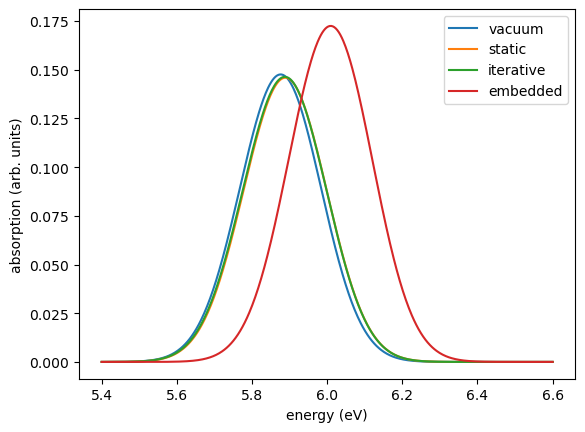

In [6]:
grid = np.linspace(5.4, 6.6, 600)
for name, (energy, strength) in spectra.items():
    spectrum = sum(f * np.exp(-0.5 * ((grid - e) / 0.1)**2) for e, f in zip(energy, strength))
    plt.plot(grid, spectrum, label=name)
plt.xlabel("energy (eV)")
plt.ylabel("absorption (arb. units)")
plt.legend()
plt.show()

## Summary

* `qmmm` jobs combine a QM region (DFT and GW-BSE) with static and polarizable classical regions; the states of the job (`n`, `s1`, ...) and the regions are set in the options and in the job file.
* For neutral excitations in a nonpolar environment, the electrostatic field and the state-specific polarization (static and iterative schemes) cause small shifts.
* The embedded scheme adds the environment's response to the correlated motion of electron and hole: the polarization of the quasiparticles and the screening of the electron-hole attraction, which are large individually and largely cancel in the excitation energy. It needs one GW-BSE run instead of one per iteration.
* With a small QM region and a 1 nm polarizable shell this tutorial runs in about a minute; production calculations need a converged environment (larger polarizable region, or the periodic Ewald background of the charge-transport tutorial) and several molecules for statistics.